# Method 2 of creating SubGraph.

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os

In [2]:
load_dotenv()

True

In [3]:
os.environ["LANGSMITH_PROJECT"] = "Subgraph Example_2"

In [4]:
# Initializing the model
model = ChatOpenAI(model="gpt-3.5-turbo")

In [5]:
class ParentState(TypedDict):
    question: str
    english_answer: str
    hindi_answer: str

In [7]:
# Defining the translation node

def translation_node(state: ParentState):
    text = state['english_answer']

    prompt = f'''Translate the below given text into Hindi. Do not add any extra comments.
    
    Text: {text}
    '''

    translated_text = model.invoke(prompt)

    return {'hindi_answer': translated_text.content.strip()}

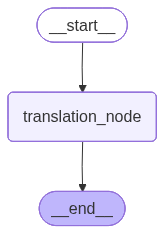

In [8]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translation_node', translation_node)

# Creating edges
subgraph_builder.add_edge(START, 'translation_node')

subgraph = subgraph_builder.compile()

subgraph

In [9]:
# Defining answer node
def generate_answer(state: ParentState):
    question = state['question']

    prompt = f'''Answer the below given question.
    
    Question: {question}'''

    answer = model.invoke(prompt).content.strip()

    return {'english_answer': answer}

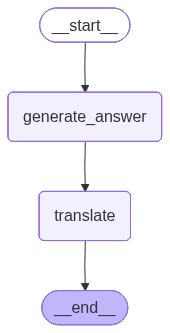

In [10]:
parent_builder = StateGraph(ParentState)

# Adding nodes
parent_builder.add_node('generate_answer', generate_answer)
parent_builder.add_node('translate', subgraph)


# Adding edges
parent_builder.add_edge(START, 'generate_answer')
parent_builder.add_edge('generate_answer', 'translate')

final_workflow = parent_builder.compile()

final_workflow


In [14]:
initial_input = {
    'question': 'Considering all indian shashtras and saints sayings, make me believe that NAAM JAPP will keep Bhagwan Krishna with me and save me from every sorrows and circumstances.'
}

response = final_workflow.invoke(initial_input)

response

{'question': 'Considering all indian shashtras and saints sayings, make me believe that NAAM JAPP will keep Bhagwan Krishna with me and save me from every sorrows and circumstances.',
 'english_answer': 'In Indian scriptures and teachings by saints, it is believed that repeating the name of God, or "NAAM JAPP," can bring one closer to the divine and offer protection from all sorrows and challenges. By continuously chanting the name of Bhagwan Krishna, one forms a deep spiritual connection with Him and invites His presence into their lives. This practice reminds us of the eternal love and grace of Bhagwan Krishna, offering comfort and support in times of need. Trusting in the power of NAAM JAPP can bring peace and guidance, ultimately protecting us from all difficulties and leading us towards a life filled with divine blessings.',
 'hindi_answer': 'भारतीय शास्त्रों और संतों द्वारा शिक्षाएं मिलने के अनुसार माना जाता है कि परमात्मा का नाम बार-बार दोहराने या "नाम जप" करने से एक व्यक्ति को 

In [15]:
response['hindi_answer']

'भारतीय शास्त्रों और संतों द्वारा शिक्षाएं मिलने के अनुसार माना जाता है कि परमात्मा का नाम बार-बार दोहराने या "नाम जप" करने से एक व्यक्ति को ईश्वर के पास ले जाया जा सकता है और सभी दुःख और चुनौतियों से सुरक्षा प्रदान की जा सकती है। भगवान कृष्ण के नाम का सतत जाप करके, व्यक्ति उसके साथ एक गहरा आध्यात्मिक संबंध बनाता है और उसके जीवन में उसके हाजिरी को आमंत्रित करता है। यह अभ्यास हमें भगवान कृष्ण की अनन्त प्रेम और कृपा की याद दिलाता है, जिसे हमें जरूरत के समय में आराम और समर्थन प्रदान करता है। नाम जप की शक्ति में विश्वास करना शांति और मार्गदर्शन लाने में सहायक हो सकता है, और अंततः हमें सभी कठिनाइयों से सुरक्षा प्रदान करके हमें दिव्य आशीर्वादों से भरा जीवन की ओर ले जा सकता है।'